# Example of the `aitlas` toolbox in the context of multi class image classification

This notebook shows a sample implementation of a multi class image classification using the `aitlas` toolbox and the WHU-RS19 dataset.

In [ ]:
from aitlas.datasets import WHURS19Dataset
from aitlas.models import ResNet50
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/WHU-RS19/images/", 
    "csv_file": "./data/WHU-RS19/train.csv"
    }
dataset = WHURS19Dataset(dataset_config)
print(len(dataset))

570


## Show images from the dataset

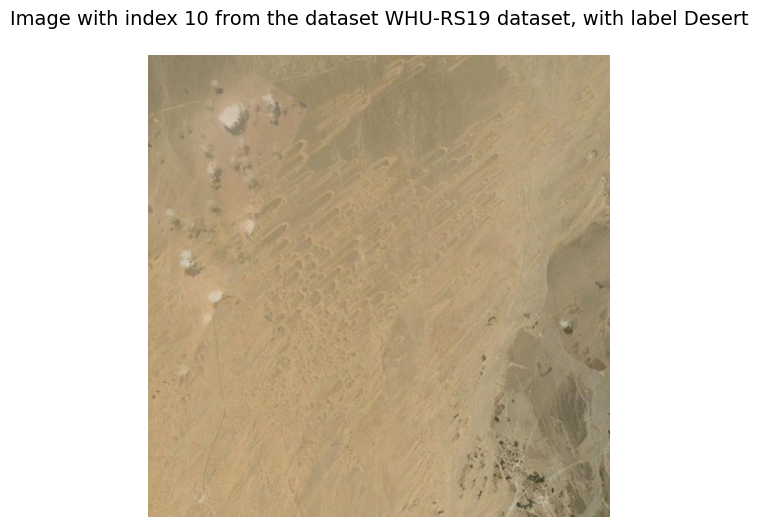

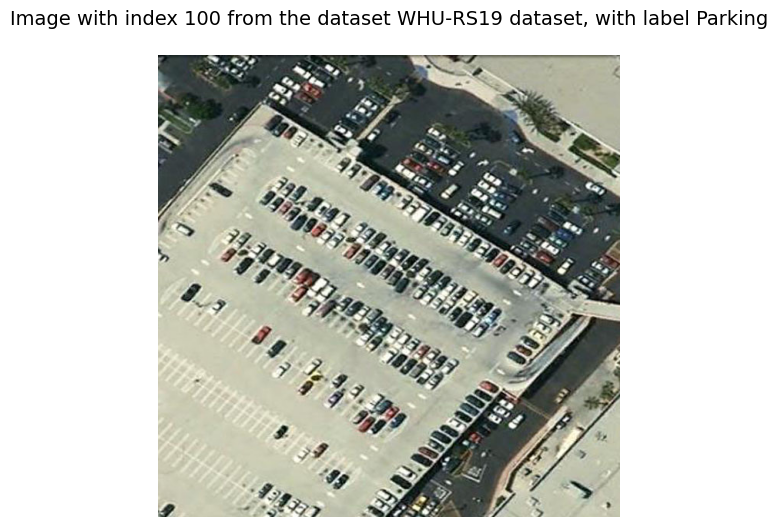

In [27]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(100)

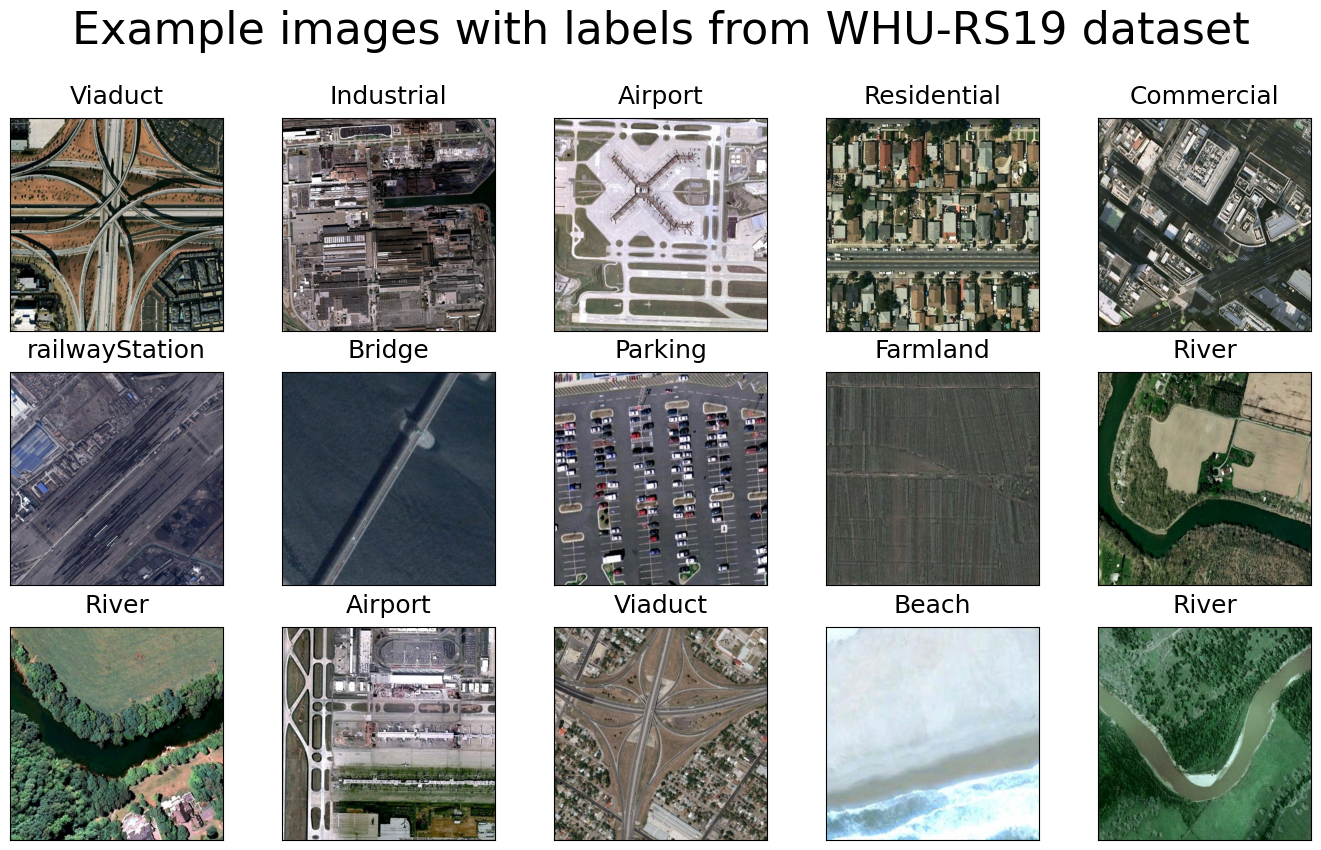

In [26]:
fig3 = dataset.show_batch(15)

## Inspect the data

In [28]:
dataset.show_samples()

,File name,Label
0,Viaduct/viaduct_05.jpg,Viaduct
1,Meadow/meadow_06.jpg,Meadow
2,Forest/forest_33.jpg,Forest
3,Beach/beach-24.jpg,Beach
4,Pond/pond_44.jpg,Pond
5,Mountain/Mountain_24.jpg,Mountain
6,River/river_25.jpg,River
7,Airport/airport_21.jpg,Airport
8,Meadow/meadow_25.jpg,Meadow
9,Commercial/commercial_17.jpg,Commercial


In [29]:
dataset.data_distribution_table()

,Label,Count
0,Airport,28
1,Beach,31
2,Bridge,27
3,Commercial,35
4,Desert,30
5,Farmland,29
6,Forest,35
7,Industrial,27
8,Meadow,32
9,Mountain,28


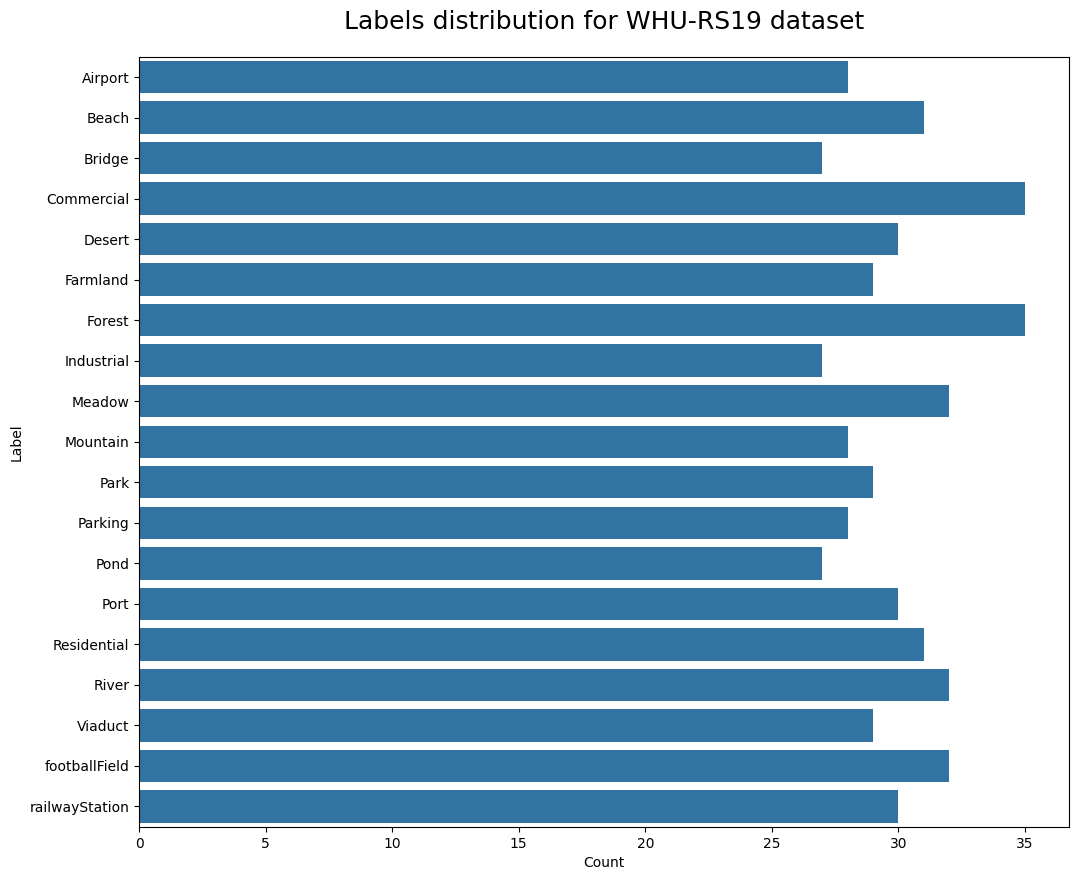

In [30]:
fig = dataset.data_distribution_barchart()

## Load train and test splits

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/WHU-RS19/images/", 
    "csv_file": "./data/WHU-RS19/train.csv"
}

train_dataset = WHURS19Dataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor()

test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/WHU-RS19/images/", 
    "csv_file": "./data/WHU-RS19/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"],
}

test_dataset = WHURS19Dataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(570, 190)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/WHU-RS19"
model_config = {
    "num_classes": 19,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"],
}
model = ResNet50(model_config)
model.prepare()

## Training and evaluation

In [33]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id="1",
)

2026-08-24 13:25:13,160 INFO Starting training.
training: 100%|██████████| 36/36 [00:02<00:00, 13.64it/s]
2026-08-24 13:25:15,882 INFO epoch: 1, time: 2, loss:  2.93275
testing on train set: 100%|██████████| 36/36 [00:01<00:00, 26.01it/s]
2026-08-24 13:25:17,918 INFO Accuracy:0.25263157894736843, Precision Micro:0.25263157894736843, Precision Macro:0.3362309157342571, Precision Weighted:0.3365260522334831, Precision per Class:[0.10526316 0.         0.16129032 0.375      0.92307692 1.
 0.         0.66666667 0.         0.         1.         0.25
 0.72727273 0.         0.         0.45098039 0.34883721 0.13
 0.25      ], Recall Micro:0.25263157894736843, Recall Macro:0.2515989137037378, Recall Weighted:0.25263157894736843, Recall per Class:[0.14285714 0.         0.74074074 0.17142857 0.4        0.20689655
 0.         0.28571429 0.         0.         0.03571429 0.10344828
 0.28571429 0.         0.         0.76666667 0.48387097 0.8125
 0.34482759], F1_score Micro:0.25263157894736793, F1_scor

0.11008542932962116

## Predictions

2026-08-24 13:26:47,292 INFO Loading checkpoint /home/dragik/data/experiments/WHU-RS19/checkpoint.pth.tar
2026-08-24 13:26:47,701 INFO Loaded checkpoint /home/dragik/data/experiments/WHU-RS19/checkpoint.pth.tar at epoch 11


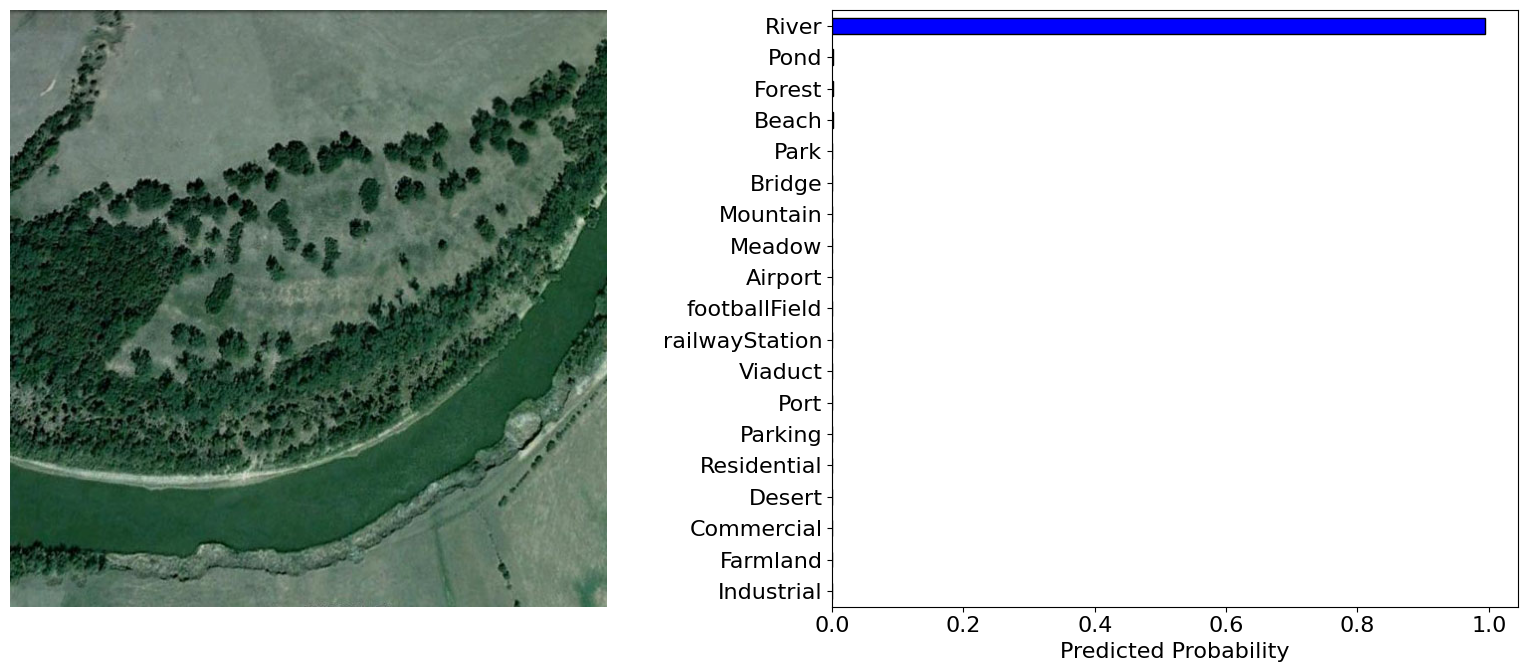

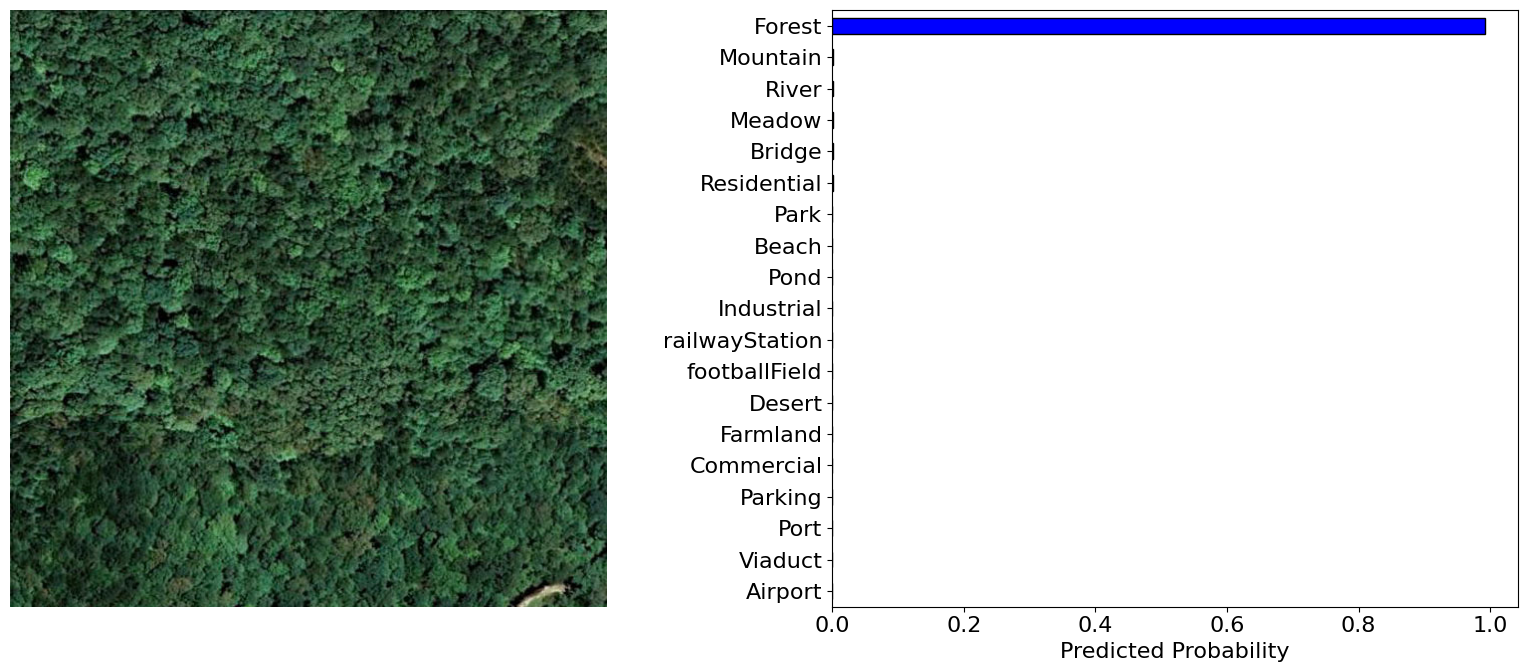

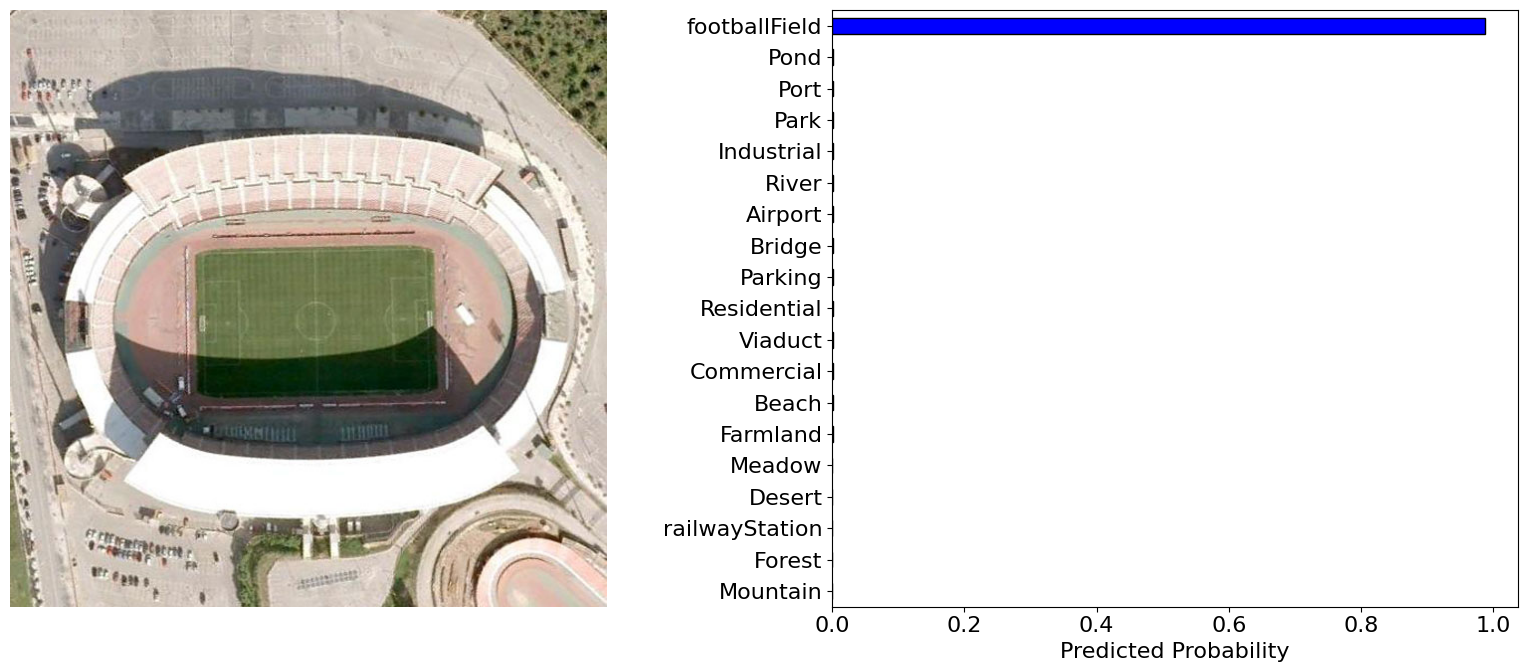

In [ ]:
model_path = "./data/experiments/WHU-RS19/checkpoint.pth.tar"
labels = [
    "Airport",
    "Beach",
    "Bridge",
    "Commercial",
    "Desert",
    "Farmland",
    "footballField",
    "Forest",
    "Industrial",
    "Meadow",
    "Mountain",
    "Park",
    "Parking",
    "Pond",
    "Port",
    "railwayStation",
    "Residential",
    "River",
    "Viaduct",
]
transform = ResizeCenterCropToTensor()
model.load_model(model_path)

image = image_loader("./data/WHU-RS19/images/River/river_43.jpg")
fig = model.predict_image(image, labels, transform)

image = image_loader("./data/WHU-RS19/images/Forest/forest_02.jpg")
fig = model.predict_image(image, labels, transform)

image = image_loader("./data/WHU-RS19/images/footballField/footballField_14.jpg")
fig = model.predict_image(image, labels, transform)